# 05 · Development value: what could land readjustment around the south portal fund?

Notebook 04 showed the tunnel adds only tens of millions to **existing** homes. The
bigger prize is **new homes** on land pooled and replanned around the Rotherhithe
portal. This notebook sizes that prize with deliberately simple, editable scenarios.

**Method**

1. **Readjustment area**: land within `RADIUS_M` of the south portal. We take
   Census output areas clipped to the riverbank, then remove parks, open space,
   docks and water, schools and churches (OpenStreetMap).
2. **Existing density**: Census 2021 households per hectare. The Isle of Dogs
   side of the river is the comparison.
3. **Scenarios**: redevelop a share of the developable land at a target density.
   Net new homes = redeveloped area × (target − existing density).
4. **Land value per new home**, from MHCLG _Land value estimates for policy
   appraisal 2023_: Southwark residential land with planning permission, £/ha ÷
   the dwellings/ha it assumes.
5. **Tunnel premium**: the % price uplift from notebook 04, applied to the sale value
   of the new homes. Build costs don't change, so this adds one-for-one to land value.
6. **Replacement cost**: homes demolished on redeveloped land are rebuilt for their
   occupants at build cost, with no sale income.
7. **Funding**: in land readjustment, a _reserve share_ of the pooled land is
   sold to pay for infrastructure. Funding capacity ≈ reserve share × gross
   development land value. What is left must still cover replacement homes
   and leave owners better off.

8. **Phasing and discounting**: new homes are built out at `DELIVERY_PER_YEAR`,
   and reserve land is sold in tranches ahead of each year's completions. Present
   values use the Green Book 3.5% real discount rate, with 7% as a
   commercial-borrowing sensitivity.

All money is in 2025 prices: MHCLG's 2023 land values are uplifted with the GDP
deflator, and there is no real land-value growth. This is a sizing exercise, not
a viability appraisal.

Contains MHCLG, ONS and HM Land Registry data (OGL v3.0) and OpenStreetMap data (ODbL).


In [ ]:
import os
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
from shapely.geometry import Point

from common import (
    BNG,
    DERIVED,
    FIGURES,
    NORTH_PORTAL,
    RAW,
    SOUTH_PORTAL,
    WGS84,
    ons_layer,
    to_bng,
)

RADIUS_M = int(os.environ.get("RADIUS_M", "750"))  # override with env var for sensitivity runs

# --- Assumptions (edit and re-run) -----------------------------------------
REDEVELOP_SHARES = [0.20, 0.35, 0.50]  # share of developable land actually rebuilt
TARGET_DENSITIES = [260, 400]  # homes/ha: Southwark "high" in MHCLG; Tower Hamlets "high"
RESERVE_SHARES = [0.30, 0.40]  # land kept back and sold to fund infrastructure (Misato ~35-40%)
BUILD_COST_PER_HOME = 340_000  # replacement home: ~85 m² GIA × £4,000/m², all-in (assumption, not BCIS)

# Phasing (years counted from the decision to proceed; year 0 = today)
DELIVERY_PER_YEAR = 500  # net new homes completed per year (sensitivity below)
FIRST_COMPLETIONS_YEAR = 6  # masterplan, readjustment vote and planning, then build, alongside the tunnel
LAND_SALE_LEAD_YEARS = 2  # each tranche of reserve land sells ~2 years before its homes complete
DISCOUNT_RATES = {"3.5% (Green Book)": 0.035, "7% (commercial)": 0.07}

## 1 · Readjustment area


In [ ]:
south = Point(to_bng(SOUTH_PORTAL))
north = Point(to_bng(NORTH_PORTAL))
area_south = south.buffer(RADIUS_M)
area_north = north.buffer(RADIUS_M)

oa = ons_layer("Output_Areas_2021_EW_BGC_V2").to_crs(BNG)[["OA21CD", "LSOA21NM", "geometry"]]
oa["borough"] = oa["LSOA21NM"].str.rsplit(" ", n=1).str[0]
with zipfile.ZipFile(RAW / "ts044.zip") as z, z.open("census2021-ts044-oa.csv") as f:
    hh = pd.read_csv(f, usecols=["geography code", "Accommodation type: Total: All households"])
hh.columns = ["OA21CD", "households"]
oa = oa.merge(hh, on="OA21CD")
oa["oa_area"] = oa.area


def constraints(bbox) -> gpd.GeoDataFrame:
    path = RAW / f"constraints_osm_{RADIUS_M}m.gpkg"
    if path.exists():
        return gpd.read_file(path)
    tags: dict[str, bool | str | list[str]] = {
        "leisure": ["park", "nature_reserve", "playground", "pitch", "garden", "common"],
        "landuse": ["recreation_ground", "cemetery", "grass", "village_green"],
        "amenity": ["school", "place_of_worship"],
        "natural": ["water"],
        "water": True,
    }
    f = ox.features_from_bbox(bbox, tags=tags)
    f = f[f.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
    is_water = (f.get("natural") == "water") | f.get("water").notna()
    is_comm = f.get("amenity").isin(["school", "place_of_worship"])
    f["class"] = np.select([is_water, is_comm], ["water", "community"], "open_space")
    f = f[["class", "name", "geometry"]].reset_index(drop=True)
    f.to_file(path)
    return f


both = gpd.GeoSeries([area_south, area_north], crs=BNG).to_crs(WGS84).total_bounds
cons = constraints(tuple(both)).to_crs(BNG)


def study(area, borough) -> gpd.GeoDataFrame:
    """OA pieces inside `area` on one bank (by borough), households prorated, constraints removed."""
    pieces = gpd.clip(oa[oa.borough == borough], area)
    pieces["households"] = pieces.households * pieces.area / pieces.oa_area
    blocked = cons.union_all()
    pieces["gross_ha"] = pieces.area / 1e4
    pieces["geometry"] = pieces.geometry.difference(blocked)
    pieces["developable_ha"] = pieces.area / 1e4
    return pieces


south_oa = study(area_south, "Southwark")
north_oa = study(area_north, "Tower Hamlets")

pd.DataFrame(
    {
        side: {
            "land within radius (ha)": d.gross_ha.sum(),
            "developable after removing parks, water, schools (ha)": d.developable_ha.sum(),
            "households (Census 2021)": d.households.sum(),
            "density: households per developable ha": d.households.sum() / d.developable_ha.sum(),
        }
        for side, d in [("South (Rotherhithe)", south_oa), ("North (Isle of Dogs)", north_oa)]
    }
).round(1)

,South (Rotherhithe),North (Isle of Dogs)
land within radius (ha),82.3,108.1
"developable after removing parks, water, schools (ha)",59.0,87.2
households (Census 2021),3674.7,7312.3
density: households per developable ha,62.3,83.8


The north circle has _fewer_ households per hectare than the south because much of
it is offices, so it's a poor residential benchmark. Target densities come from
MHCLG's "high density" assumptions instead: 260 homes/ha for Southwark, 400 for Tower Hamlets.

**Caveats on the land values below**

- At 400 homes/ha we keep Southwark's per-home land value from its 260/ha assumption.
  Taller buildings cost more per home, so this probably overstates the 400/ha scenarios.
- Check the MHCLG guidance on what the estimates assume about affordable housing
  and planning obligations before quoting them.


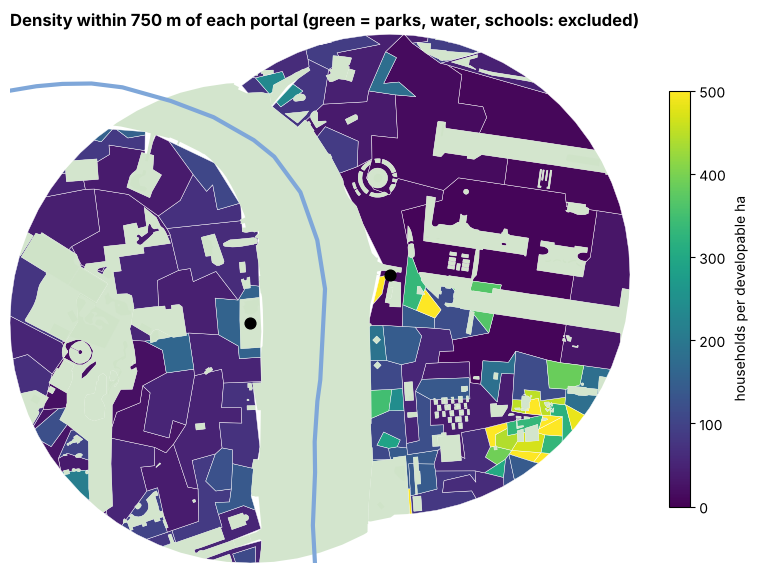

In [ ]:
fig, ax = plt.subplots(figsize=(10, 9))
for d in (south_oa, north_oa):
    d.plot(
        ax=ax,
        column=d.households / d.developable_ha.replace(0, np.nan),
        cmap="viridis",
        vmin=0,
        vmax=500,
        edgecolor="white",
        linewidth=0.3,
    )
gpd.clip(cons, area_south.union(area_north)).plot(ax=ax, color="#cfe3c8", alpha=0.9)
gpd.read_file(RAW / "thames.gpkg").to_crs(BNG).plot(ax=ax, color="#7fa7d9", linewidth=3)
gpd.GeoSeries([south, north], crs=BNG).plot(ax=ax, color="black", markersize=60)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(0, 500))
fig.colorbar(sm, ax=ax, shrink=0.6, label="households per developable ha")
xmin, ymin, xmax, ymax = area_south.union(area_north).bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axis_off()
ax.set_title(
    f"Density within {RADIUS_M} m of each portal (green = parks, water, schools: excluded)",
    loc="left",
    fontweight="bold",
)
fig.savefig(FIGURES / "05_density.png", dpi=150, bbox_inches="tight")

## 2 · Land value per new home (MHCLG 2023)


In [ ]:
lv = pd.read_excel(RAW / "land_values_2023.xlsx", sheet_name="Residential", header=None, skiprows=5)
lv = lv.iloc[:, 1:22]
lv.columns = ["region", "la_code", "la", "dph_low", "dph_med", "dph_high"] + [
    f"{d}_{p}" for d in ("low", "med", "high") for p in (25, 40, 50, 60, 75)
]
southwark = lv[lv.la == "Southwark"].iloc[0]
defl = pd.read_csv(RAW / "gdp_deflator.csv", skiprows=8, header=None, names=["period", "index"])
defl = defl[defl.period.str.fullmatch(r"\d{4}")].astype({"period": int, "index": float}).set_index("period")["index"]
TO_2025 = defl[2025] / defl[2023]
lv_per_home = {p: southwark[f"high_{p}"] / southwark["dph_high"] * TO_2025 for p in (40, 50, 60)}
print(f"Southwark high-density assumption: {southwark.dph_high:.0f} homes/ha")
for p, v in lv_per_home.items():
    print(
        f"  {p}th house-price percentile: £{southwark[f'high_{p}'] / 1e6:.1f}m/ha (2023) → £{v:,.0f} per home (2025 prices)"
    )

Southwark high-density assumption: 260 homes/ha
  40th house-price percentile: £54.3m/ha (2023) → £225,093 per home (2025 prices)
  50th house-price percentile: £63.6m/ha (2023) → £263,616 per home (2025 prices)
  60th house-price percentile: £74.6m/ha (2023) → £308,933 per home (2025 prices)


## 3 · Tunnel premium on new homes


In [ ]:
sales = pd.read_csv(DERIVED / "sales.csv")
new_flats = sales[
    (sales.district == "SE16") & (sales.new_build == "Y") & (sales.property_type == "F") & (sales.year >= 2021)
]
new_home_price = new_flats.price.median()
print(f"Median SE16 new-build flat price 2021+: £{new_home_price:,.0f} (n={len(new_flats)})")

oa_uplift = pd.read_csv(DERIVED / "oa_uplift.csv").set_index("OA21CD")
w = south_oa.set_index("OA21CD").developable_ha
premium = {
    s: float(
        (oa_uplift.reindex(w.index)[f"uplift_pct_{s}"] * w).sum()
        / w[oa_uplift.reindex(w.index)[f"uplift_pct_{s}"].notna()].sum()
    )
    for s in ("Low", "Central", "High")
}
print(
    "Area-weighted tunnel price premium in the south readjustment area:", {k: f"{v:.1%}" for k, v in premium.items()}
)

Median SE16 new-build flat price 2021+: £610,000 (n=115)
Area-weighted tunnel price premium in the south readjustment area: {'Low': '2.1%', 'Central': '3.5%', 'High': '25.8%'}


## 4 · Scenarios


In [ ]:
dev_ha = south_oa.developable_ha.sum()
existing_dph = south_oa.households.sum() / dev_ha
rows = []
for share in REDEVELOP_SHARES:
    for target in TARGET_DENSITIES:
        redeveloped_ha = dev_ha * share
        demolished = redeveloped_ha * existing_dph
        net_new = redeveloped_ha * max(target - existing_dph, 0)
        for prem_case in ("Central", "High"):
            land_value = net_new * (lv_per_home[50] + premium[prem_case] * new_home_price)
            tunnel_part = net_new * premium[prem_case] * new_home_price
            replacement = demolished * BUILD_COST_PER_HOME
            for reserve in RESERVE_SHARES:
                funding = reserve * land_value
                rows.append(
                    {
                        "redeveloped share": f"{share:.0%}",
                        "target homes/ha": target,
                        "tunnel premium case": prem_case,
                        "reserve share": f"{reserve:.0%}",
                        "redeveloped ha": redeveloped_ha,
                        "homes demolished & replaced": demolished,
                        "net new homes": net_new,
                        "development land value (£m)": land_value / 1e6,
                        "  of which due to tunnel (£m)": tunnel_part / 1e6,
                        "replacement build cost (£m)": replacement / 1e6,
                        "reserve land funding (£m)": funding / 1e6,
                        "left for owners after replacement (£m)": (land_value - funding - replacement) / 1e6,
                    }
                )
scen = pd.DataFrame(rows)
print(f"Developable land: {dev_ha:.1f} ha at {existing_dph:.0f} homes/ha today")
scen.round(0)

Developable land: 59.0 ha at 62 homes/ha today


,redeveloped share,target homes/ha,tunnel premium case,reserve share,redeveloped ha,homes demolished & replaced,net new homes,development land value (£m),of which due to tunnel (£m),replacement build cost (£m),reserve land funding (£m),left for owners after replacement (£m)
0,20%,260,Central,30%,12.0,735.0,2335.0,666.0,50.0,250.0,200.0,216.0
1,20%,260,Central,40%,12.0,735.0,2335.0,666.0,50.0,250.0,266.0,150.0
2,20%,260,High,30%,12.0,735.0,2335.0,983.0,368.0,250.0,295.0,438.0
3,20%,260,High,40%,12.0,735.0,2335.0,983.0,368.0,250.0,393.0,340.0
4,20%,400,Central,30%,12.0,735.0,3987.0,1137.0,86.0,250.0,341.0,546.0
5,20%,400,Central,40%,12.0,735.0,3987.0,1137.0,86.0,250.0,455.0,432.0
6,20%,400,High,30%,12.0,735.0,3987.0,1679.0,628.0,250.0,504.0,925.0
7,20%,400,High,40%,12.0,735.0,3987.0,1679.0,628.0,250.0,672.0,757.0
8,35%,260,Central,30%,21.0,1286.0,4086.0,1165.0,88.0,437.0,349.0,378.0
9,35%,260,Central,40%,21.0,1286.0,4086.0,1165.0,88.0,437.0,466.0,262.0


### Headline: central premium, 35% reserve-equivalent range


In [ ]:
head = scen[(scen["tunnel premium case"] == "Central")]
pivot = head.pivot_table(
    index=["redeveloped share", "target homes/ha"], columns="reserve share", values="reserve land funding (£m)"
).round(0)
pivot

reserve share                        30%     40%
redeveloped share target homes/ha               
20%               260              200.0   266.0
                  400              341.0   455.0
35%               260              349.0   466.0
                  400              597.0   796.0
50%               260              499.0   666.0
                  400              853.0  1137.0

## 5 · Phasing and discounting

Build-out takes `net new homes / DELIVERY_PER_YEAR` years. Reserve-land receipts
(and replacement-home costs) follow the same schedule, with land sold
`LAND_SALE_LEAD_YEARS` ahead of completions. The _PV factor_ is the average
discount factor across that schedule.


In [ ]:
def pv_factor(net_new: float, rate: float, per_year: float = DELIVERY_PER_YEAR) -> float:
    if net_new <= 0:
        return 1.0
    full, part = divmod(net_new, per_year)
    tranches = [per_year] * int(full) + ([part] if part else [])
    first = FIRST_COMPLETIONS_YEAR - LAND_SALE_LEAD_YEARS
    return sum(n / (1 + rate) ** (first + i) for i, n in enumerate(tranches)) / net_new


scen["build-out years"] = np.ceil(scen["net new homes"] / DELIVERY_PER_YEAR)
for label, rate in DISCOUNT_RATES.items():
    f = scen["net new homes"].map(lambda n, rate=rate: pv_factor(n, rate))
    scen[f"PV reserve funding @ {label} (£m)"] = scen["reserve land funding (£m)"] * f
    scen[f"PV left for owners @ {label} (£m)"] = scen["left for owners after replacement (£m)"] * f

head = scen[scen["tunnel premium case"] == "Central"]
head.pivot_table(
    index=["redeveloped share", "target homes/ha", "build-out years"],
    columns="reserve share",
    values=["reserve land funding (£m)"] + [f"PV reserve funding @ {l} (£m)" for l in DISCOUNT_RATES],
).round(0)

PV reserve funding @ 3.5% (Green Book) (£m)  \
reserve share                                                                             30%   
redeveloped share target homes/ha build-out years                                               
20%               260             5.0                                                   163.0   
                  400             8.0                                                   264.0   
35%               260             9.0                                                   270.0   
                  400             14.0                                                  420.0   
50%               260             12.0                                                  364.0   
                  400             20.0                                                  547.0   

                                                          \
reserve share                                        40%   
redeveloped share target homes/ha build-out years          
20%               260             5.0              218.0   
                  400             8.0              353.0   
35%               260             9.0              360.0   
                  400             14.0             560.0   
50%               260             12.0             486.0   
                  400             20.0             729.0   

                                                  PV reserve funding @ 7% (commercial) (£m)  \
reserve share                                                                           30%   
redeveloped share target homes/ha build-out years                                             
20%               260             5.0                                                 135.0   
                  400             8.0                                                 208.0   
35%               260             9.0                                                 212.0   
                  400             14.0                                                305.0   
50%               260             12.0                                                272.0   
                  400             20.0                                                369.0   

                                                          \
reserve share                                        40%   
redeveloped share target homes/ha build-out years          
20%               260             5.0              180.0   
                  400             8.0              277.0   
35%               260             9.0              282.0   
                  400             14.0             406.0   
50%               260             12.0             363.0   
                  400             20.0             492.0   

                                                  reserve land funding (£m)  \
reserve share                                                           30%   
redeveloped share target homes/ha build-out years                             
20%               260             5.0                                 200.0   
                  400             8.0                                 341.0   
35%               260             9.0                                 349.0   
                  400             14.0                                597.0   
50%               260             12.0                                499.0   
                  400             20.0                                853.0   

                                                           
reserve share                                         40%  
redeveloped share target homes/ha build-out years          
20%               260             5.0               266.0  
                  400             8.0               455.0  
35%               260             9.0               466.0  
                  400             14.0              796.0  
50%               260             12.0              666.0  
                  400             20.0        

### Sensitivity: delivery rate

Headline scenario (35% rebuilt @ 400/ha, 40% reserve, central premium): PV of reserve
funding at 3.5% for different build-out speeds.


In [ ]:
h = head[
    (head["redeveloped share"] == "35%") & (head["target homes/ha"] == 400) & (head["reserve share"] == "40%")
].iloc[0]
pd.DataFrame(
    {
        f"{rate} homes/yr": {
            "build-out years": np.ceil(h["net new homes"] / rate),
            **{
                f"PV @ {l} (£m)": h["reserve land funding (£m)"] * pv_factor(h["net new homes"], r, rate)
                for l, r in DISCOUNT_RATES.items()
            },
        }
        for rate in (300, 500, 800, 1200)
    }
).round(0)

,300 homes/yr,500 homes/yr,800 homes/yr,1200 homes/yr
build-out years,24.0,14.0,9.0,6.0
PV @ 3.5% (Green Book) (£m),486.0,560.0,609.0,639.0
PV @ 7% (commercial) (£m),316.0,406.0,474.0,519.0


In [10]:
scen.to_csv(DERIVED / f"development_scenarios_{RADIUS_M}m.csv", index=False)